# Sampler comparison — `pdo_four_substrates_doe_compare.yaml`

The design space is read from the config; every generator is pushed through the same unit-cube mapping and scored as
fabricated on four metrics (centered L2 discrepancy ↓, min pairwise distance ↑, max |factor correlation| ↓ with structural
pairs excluded, fill distance ↓ against feasible probe points). Studies: one batch over seeds (§2), cumulative batches (§3),
seed screening (§4), the correlation-weight sweep with its Pareto front (§5), and the chosen design with its run sheet and
figures (§6).

**Nothing is written to disk by default.** Every figure / table cell starts with `SAVE_* = False` and a `*_FILE` name; set a
flag to True to write that one item into `OUT_DIR`.

In [1]:
import os, sys, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
PACKAGE_DIR = '/data/zhq7531/IDEAL/DMREF/doe_compare'   # where the doe_compare package lives (None = this repository)
REPO = '/data/zhq7531/IDEAL/DMREF/repository_dmref' or next(p for p in [os.path.abspath('.'), os.path.abspath('..')] if os.path.isdir(os.path.join(p, 'doe_compare')))
sys.path.insert(0, PACKAGE_DIR or REPO); os.chdir(REPO)
import doe_compare as dc
from doe_compare import plots
from doe_compare.metrics import KEYS

CONFIG = 'doe/pdo/pdo_four_substrates_doe_compare.yaml'
cfg = dc.load_config(CONFIG); st = cfg['study']; space = dc.space_from_config(cfg)
N, REPS, GUARD = st['n'], st['repetitions'], st['guard']
W = st['corr_weight']                                         # correlation weight carried into the comparisons
WORKERS = st.get('workers')                                   # None = serial; an integer = processes; -1 = every core (results identical)
OUT_DIR = 'output/pdo/four_substrates_doe_compare' or os.path.join('doe_compare_out', 'pdo_four_substrates_doe_compare')   # where SAVE_* flags write (created on first save)
probes = space.probes(st['probes'])
CONSTANTS = cfg.get('constants', {})                      # pinned columns added to the run sheet (not design factors)
REFERENCES = {}                                           # name -> fabricated design read from a file (e.g. the sheet already exported)
for r in cfg.get('references', []):
    _df = pd.read_excel(r['path'], sheet_name=r.get('sheet', 0)); REFERENCES[r['name']] = _df[space.columns].reset_index(drop=True)
REF_METRICS = {name: dc.evaluate(space, d_, probes) for name, d_ in REFERENCES.items()}
KNOWN_DF, KNOWN_SUMMARY = dc.load_known(cfg, space)       # recipes already fabricated / measured that lie inside the bounds (config `known:`)
KNOWN = space.to_unit(KNOWN_DF[space.columns]) if len(KNOWN_DF) else None   # unit points the conditional / sliced optimisers place the batch around
SWEEP_METHOD = 'Sliced LHS' if space.slice_factor else 'LHS: CD + w×|r|'   # the optimiser whose correlation weight is swept in §5 and that builds the design in §6
CATS = [f.name for f in space.factors if f.kind == 'categorical']        # every metric is also reported for the worst level of each of these
CORR_SCOPE = st.get('corr_scope', 'whole')                               # 'whole': the |r| term of the optimisers is the pooled design; 'levels': also every level of every categorical factor
OPT_KW = dict(corr_scope=CORR_SCOPE)
SINGLE_KW = {'LHS: CD + w×|r|': dict(w=W, **OPT_KW), 'Sliced LHS': dict(corr_weight=W, **OPT_KW), 'Optimised LHS + SA': dict(**OPT_KW)}
SEQ_KW = {'Weighted LHS + conditional': dict(w=W, **OPT_KW), 'Sliced LHS, conditional': dict(corr_weight=W, **OPT_KW), 'Optimised LHS + SA, conditional': dict(**OPT_KW)}
with_known = lambda d_: pd.concat([KNOWN_DF[space.columns], d_[space.columns]], ignore_index=True) if KNOWN is not None else d_
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
print(space.name, '|', space.d, 'factors | n =', N, '| repetitions =', REPS, '| known recipes inside the bounds =', len(KNOWN_DF), '| categorical factors scored per level:', CATS, '| nothing is written unless a SAVE_* flag is True')

PdO on four substrates (Al2O3/sapphire, Al2O3/Si, TiO2/Si, HfO2/Si), anneal capped at 300 C | 11 factors | n = 92 | repetitions = 5 | known recipes inside the bounds = 56 | categorical factors scored per level: ['Substrate', 'Dep Temp (°C)', 'Ox Press (atm)'] | nothing is written unless a SAVE_* flag is True


## 1. The design space and the recipes already in hand

In [2]:
display(space.describe())
if len(KNOWN_DF):
    display(KNOWN_SUMMARY)                     # per file: recipes, inside the bounds (kept as known locations), dropped
    display(KNOWN_DF.groupby(['source'] + ([space.slice_factor] if space.slice_factor else []), sort=False).size().rename('recipes').to_frame())

,factor,kind,range,step,note
0,Substrate,categorical,Al2O3/sapphire / Al2O3/Si / TiO2/Si / HfO2/Si,4 levels,"Al2O3/sapphire: 0.25, Al2O3/Si: 0.25, TiO2/Si:..."
1,Dep Power (W),continuous,2 - 40,1,
2,O2 Flow (sccm),continuous,0.3 - 20,0.1,
3,Dep Press (mTorr),continuous,2 - 10,0.1,
4,Dep Temp (°C),categorical,25 / 425,2 levels,"25: 0.5, 425: 0.5"
5,Ox Temp (°C),continuous,200 - 700,5,
6,Ox Press (atm),categorical,0.02 / 1.0,2 levels,"0.02: 0.5, 1.0: 0.5"
7,Ox Time (min),continuous,0 - 120,0.1,
8,Vac Ann Temp (°C),continuous,25 - 300,5,
9,Vac Ann Time (min),continuous,0 - 120,0.1,


,source,recipes_in_file,inside_bounds,dropped
0,Al2O3/sapphire - experiment 02 films (measured),23,9,14
1,"Al2O3/Si - experiment 04 batch (fabricated, wa...",23,23,0
2,"TiO2/Si - experiment 04 batch (fabricated, wai...",23,23,0
3,"HfO2/Si - experiment 03 batch 1 (5 conditions,...",5,1,4


,,recipes
source,Substrate,
Al2O3/sapphire - experiment 02 films (measured),Al2O3/sapphire,9
"Al2O3/Si - experiment 04 batch (fabricated, waiting for data)",Al2O3/Si,23
"TiO2/Si - experiment 04 batch (fabricated, waiting for data)",TiO2/Si,23
"HfO2/Si - experiment 03 batch 1 (5 conditions, 2 measurable)",HfO2/Si,1


## 2. One batch: every generator over seeds

Every metric is scored on the whole batch and, for each categorical factor, on the worst of its levels (the batch split by that factor, each part scored on the other factors): a design can be fine pooled and confounded inside one substrate or one temperature level.

70 designs scored in 18 s


,discrepancy,min_dist,max_corr,fill_dist,discrepancy@Substrate,min_dist@Substrate,max_corr@Substrate,fill_dist@Substrate,balance@Substrate,discrepancy@Dep Temp (°C),min_dist@Dep Temp (°C),max_corr@Dep Temp (°C),fill_dist@Dep Temp (°C),balance@Dep Temp (°C),discrepancy@Ox Press (atm),min_dist@Ox Press (atm),max_corr@Ox Press (atm),fill_dist@Ox Press (atm),balance@Ox Press (atm)
method,,,,,,,,,,,,,,,,,,,
Sobol (scrambled),0.536 ± 0.001,0.475 ± 0.081,0.237 ± 0.019,1.270 ± 0.034,0.666 ± 0.013,0.475 ± 0.081,0.782 ± 0.030,1.448 ± 0.026,0.086 ± 0.027,0.310 ± 0.004,0.475 ± 0.081,0.320 ± 0.076,1.286 ± 0.021,0.061 ± 0.013,0.322 ± 0.009,0.475 ± 0.081,0.417 ± 0.136,1.284 ± 0.032,0.093 ± 0.047
Halton (scrambled),0.550 ± 0.005,0.501 ± 0.058,0.243 ± 0.037,1.314 ± 0.049,0.702 ± 0.019,0.509 ± 0.059,0.617 ± 0.093,1.485 ± 0.025,0.105 ± 0.023,0.341 ± 0.015,0.501 ± 0.058,0.350 ± 0.041,1.325 ± 0.037,0.169 ± 0.045,0.349 ± 0.022,0.501 ± 0.058,0.369 ± 0.060,1.329 ± 0.039,0.167 ± 0.069
Plain LHS,0.572 ± 0.008,0.444 ± 0.097,0.275 ± 0.022,1.318 ± 0.028,0.859 ± 0.036,0.451 ± 0.104,0.586 ± 0.034,1.546 ± 0.024,0.241 ± 0.047,0.381 ± 0.022,0.444 ± 0.097,0.371 ± 0.045,1.337 ± 0.026,0.188 ± 0.055,0.380 ± 0.020,0.444 ± 0.097,0.422 ± 0.083,1.341 ± 0.033,0.185 ± 0.049
Optimised LHS (random-CD),0.520 ± 0.001,0.599 ± 0.079,0.083 ± 0.015,1.269 ± 0.015,0.715 ± 0.022,0.622 ± 0.086,0.463 ± 0.056,1.482 ± 0.025,0.132 ± 0.028,0.296 ± 0.006,0.599 ± 0.079,0.230 ± 0.041,1.288 ± 0.021,0.070 ± 0.023,0.297 ± 0.004,0.599 ± 0.079,0.219 ± 0.025,1.288 ± 0.032,0.072 ± 0.014
LHS: CD + w×|r|,0.520 ± 0.001,0.615 ± 0.084,0.039 ± 0.004,1.265 ± 0.016,0.725 ± 0.029,0.630 ± 0.087,0.449 ± 0.048,1.489 ± 0.048,0.137 ± 0.030,0.295 ± 0.006,0.615 ± 0.084,0.212 ± 0.028,1.282 ± 0.021,0.036 ± 0.009,0.295 ± 0.005,0.615 ± 0.084,0.216 ± 0.029,1.278 ± 0.031,0.039 ± 0.004
Sliced LHS,0.523 ± 0.001,0.556 ± 0.038,0.069 ± 0.009,1.284 ± 0.029,0.554 ± 0.003,0.783 ± 0.081,0.154 ± 0.009,1.414 ± 0.022,0.025 ± 0.000,0.301 ± 0.003,0.556 ± 0.038,0.283 ± 0.024,1.306 ± 0.029,0.062 ± 0.012,0.301 ± 0.004,0.556 ± 0.038,0.296 ± 0.043,1.306 ± 0.023,0.061 ± 0.012
Uniform random,0.629 ± 0.029,0.438 ± 0.069,0.268 ± 0.048,1.347 ± 0.036,1.056 ± 0.212,0.445 ± 0.080,0.594 ± 0.069,1.574 ± 0.070,0.274 ± 0.051,0.431 ± 0.038,0.438 ± 0.069,0.424 ± 0.047,1.368 ± 0.033,0.202 ± 0.068,0.437 ± 0.037,0.438 ± 0.069,0.398 ± 0.055,1.370 ± 0.025,0.207 ± 0.039


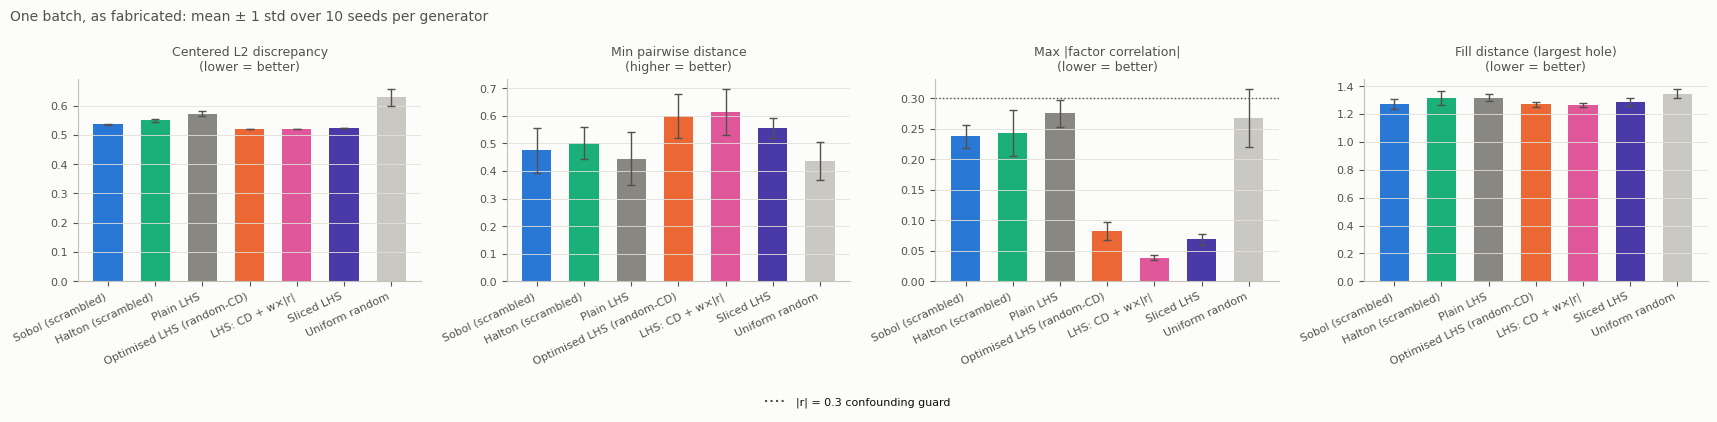

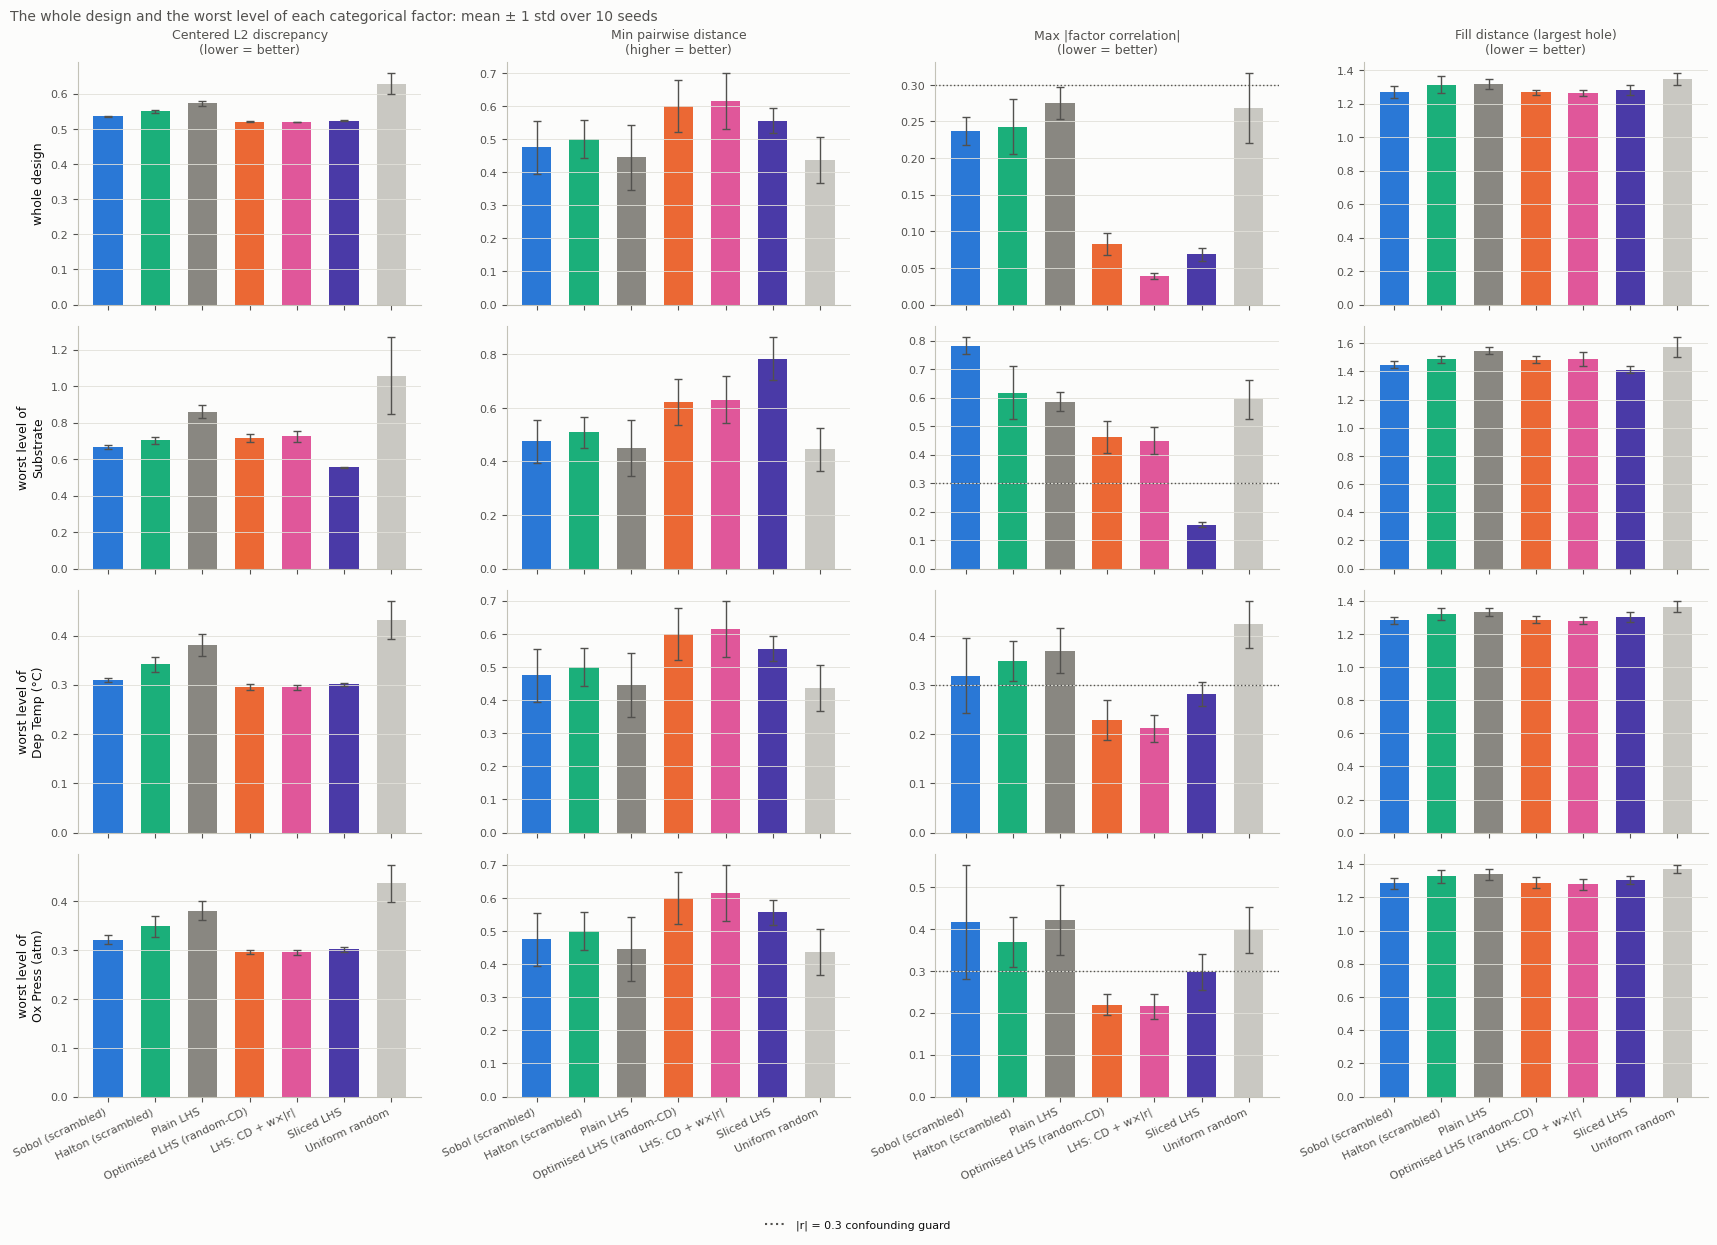

In [3]:
# ---- saving (set a flag to True to write that item)
SAVE_SINGLE_FIG = False;    SINGLE_FIG_FILE = 'single_batch.png'
SAVE_SINGLE_TABLE = False;  SINGLE_TABLE_FILE = 'single_batch.xlsx'
SAVE_SINGLE_LEVELS_FIG = False;  SINGLE_LEVELS_FIG_FILE = 'single_batch_levels.png'

t0 = time.time()
single = dc.single_batch(space, N, st['methods'], range(st['seeds']), probes, SINGLE_KW, workers=WORKERS)
text, best, mean, std = dc.summarize(single)
print(f'{len(single)} designs scored in {time.time() - t0:.0f} s')
display(text.style.apply(lambda col: ['font-weight: bold' if b else '' for b in best[col.name]]) if hasattr(text, 'style') else text)
ref_name = next(iter(REF_METRICS), None)
fig = plots.method_bars(single, star=None if ref_name is None else REF_METRICS[ref_name], star_label=f'reference: {ref_name}')
dc.save_fig(fig, SAVE_SINGLE_FIG, os.path.join(OUT_DIR, SINGLE_FIG_FILE)); plt.show()
if REF_METRICS:
    display(pd.DataFrame(REF_METRICS).T.round(3))
if CATS:
    fig = plots.level_bars(single, CATS); dc.save_fig(fig, SAVE_SINGLE_LEVELS_FIG, os.path.join(OUT_DIR, SINGLE_LEVELS_FIG_FILE)); plt.show()
dc.save_table({'per_seed': single, 'summary': text}, SAVE_SINGLE_TABLE, os.path.join(OUT_DIR, SINGLE_TABLE_FILE))

## 2b. One batch placed around the recipes already in hand

The known recipes (§1) are part of the design from the start. Sequences and fresh batch generators ignore them; the
conditional optimisers (`+ conditional`, `Sliced LHS, conditional`) place the new batch in the gaps they leave. Metrics
are those of **known + new**, so this is the comparison that matters for the batch to fabricate now.

60 batches of 92 placed around 56 known recipes, scored in 27 s


,discrepancy,min_dist,max_corr,fill_dist,discrepancy@Substrate,min_dist@Substrate,max_corr@Substrate,fill_dist@Substrate,balance@Substrate,discrepancy@Dep Temp (°C),min_dist@Dep Temp (°C),max_corr@Dep Temp (°C),fill_dist@Dep Temp (°C),balance@Dep Temp (°C),discrepancy@Ox Press (atm),min_dist@Ox Press (atm),max_corr@Ox Press (atm),fill_dist@Ox Press (atm),balance@Ox Press (atm)
method,,,,,,,,,,,,,,,,,,,
Sobol (scrambled),0.495 ± 0.001,0.393 ± 0.059,0.148 ± 0.025,1.203 ± 0.034,0.644 ± 0.015,0.398 ± 0.068,0.734 ± 0.035,1.419 ± 0.034,0.077 ± 0.025,0.259 ± 0.003,0.393 ± 0.059,0.247 ± 0.059,1.214 ± 0.028,0.052 ± 0.011,0.265 ± 0.004,0.393 ± 0.059,0.285 ± 0.069,1.229 ± 0.045,0.070 ± 0.023
Plain LHS,0.509 ± 0.002,0.392 ± 0.044,0.183 ± 0.034,1.227 ± 0.030,0.778 ± 0.041,0.392 ± 0.044,0.588 ± 0.056,1.501 ± 0.041,0.175 ± 0.034,0.287 ± 0.006,0.392 ± 0.044,0.281 ± 0.022,1.249 ± 0.041,0.123 ± 0.031,0.289 ± 0.008,0.392 ± 0.044,0.314 ± 0.048,1.256 ± 0.035,0.137 ± 0.034
Optimised LHS (random-CD),0.489 ± 0.001,0.442 ± 0.058,0.076 ± 0.009,1.210 ± 0.029,0.608 ± 0.015,0.446 ± 0.062,0.404 ± 0.063,1.438 ± 0.040,0.088 ± 0.014,0.255 ± 0.003,0.442 ± 0.058,0.187 ± 0.016,1.221 ± 0.022,0.057 ± 0.015,0.254 ± 0.003,0.442 ± 0.058,0.190 ± 0.019,1.229 ± 0.027,0.068 ± 0.014
Optimised LHS + conditional,0.493 ± 0.002,0.476 ± 0.030,0.065 ± 0.007,1.208 ± 0.025,0.762 ± 0.064,0.483 ± 0.035,0.417 ± 0.105,1.456 ± 0.038,0.098 ± 0.025,0.255 ± 0.004,0.476 ± 0.030,0.171 ± 0.018,1.219 ± 0.026,0.055 ± 0.012,0.258 ± 0.003,0.476 ± 0.030,0.179 ± 0.040,1.231 ± 0.026,0.053 ± 0.011
Weighted LHS + conditional,0.492 ± 0.001,0.476 ± 0.076,0.026 ± 0.001,1.204 ± 0.024,0.732 ± 0.040,0.488 ± 0.079,0.407 ± 0.048,1.439 ± 0.036,0.098 ± 0.022,0.255 ± 0.002,0.476 ± 0.076,0.185 ± 0.029,1.208 ± 0.022,0.025 ± 0.002,0.256 ± 0.003,0.476 ± 0.076,0.178 ± 0.020,1.219 ± 0.020,0.026 ± 0.003
"Sliced LHS, conditional",0.490 ± 0.001,0.524 ± 0.049,0.068 ± 0.015,1.200 ± 0.034,0.550 ± 0.006,0.538 ± 0.063,0.149 ± 0.014,1.379 ± 0.036,0.050 ± 0.009,0.255 ± 0.004,0.524 ± 0.049,0.192 ± 0.037,1.210 ± 0.029,0.061 ± 0.019,0.254 ± 0.003,0.524 ± 0.049,0.192 ± 0.033,1.233 ± 0.036,0.054 ± 0.009


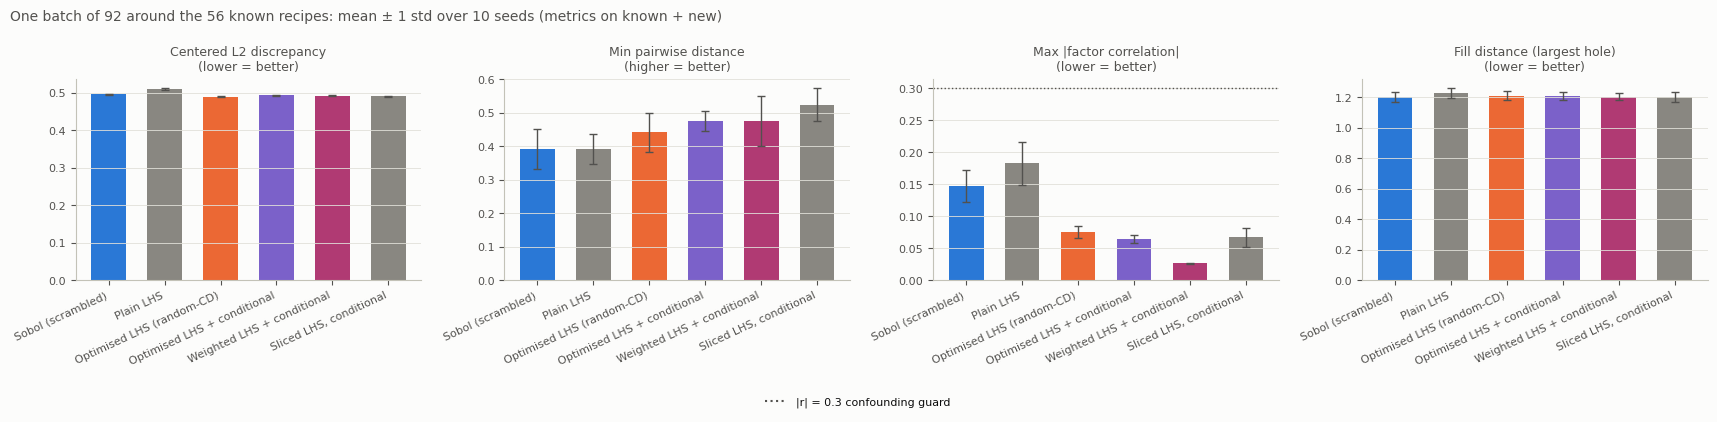

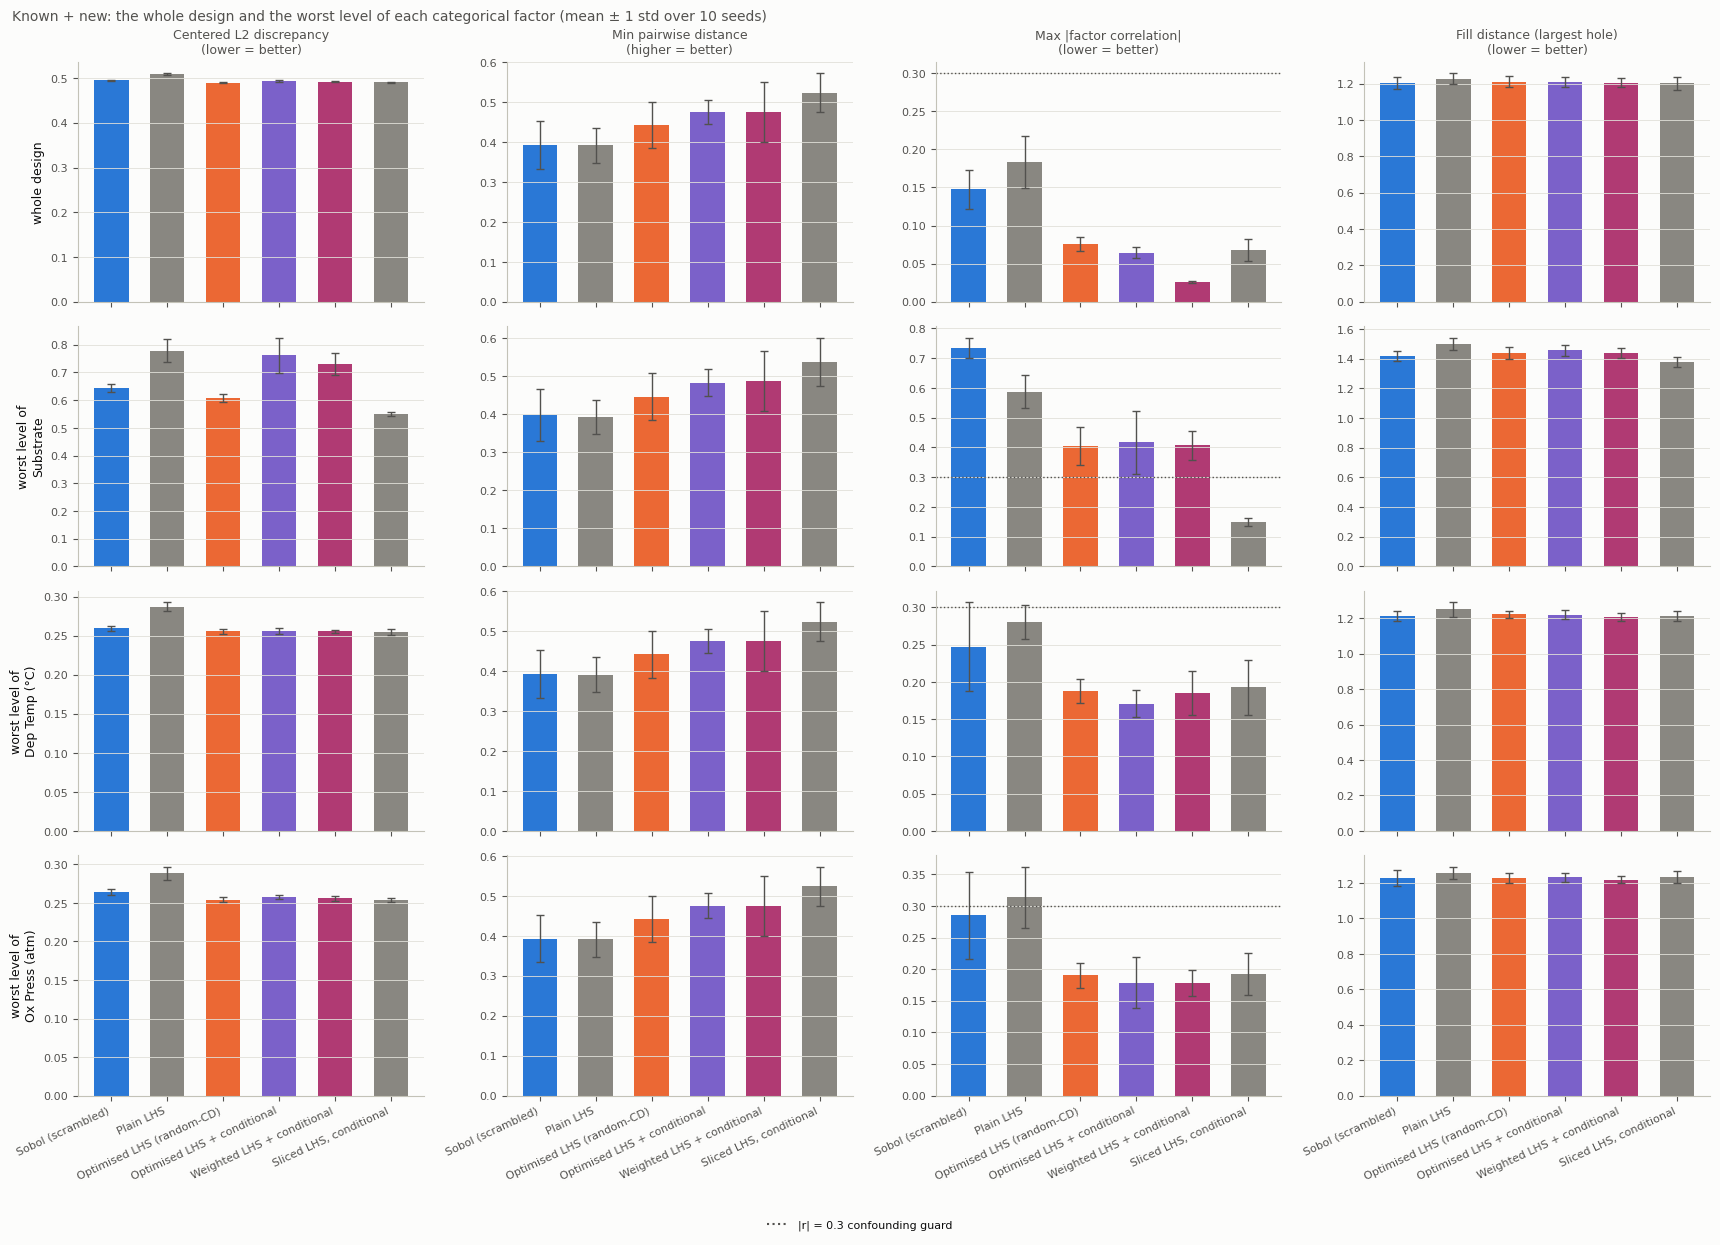

In [4]:
# ---- saving
SAVE_AROUND_FIG = False;    AROUND_FIG_FILE = 'around_known.png'
SAVE_AROUND_TABLE = False;  AROUND_TABLE_FILE = 'around_known.xlsx'
SAVE_AROUND_LEVELS_FIG = False;  AROUND_LEVELS_FIG_FILE = 'around_known_levels.png'

sq = st['sequential']; t0 = time.time()
around = dc.sequential(space, N, 1, sq['methods'], range(st['seeds']), KNOWN, probes, SEQ_KW, workers=WORKERS)
text_k, best_k, _, _ = dc.summarize(around)
print(f'{len(around)} batches of {N} placed around {len(KNOWN_DF)} known recipes, scored in {time.time() - t0:.0f} s')
display(text_k.style.apply(lambda col: ['font-weight: bold' if b else '' for b in best_k[col.name]]) if hasattr(text_k, 'style') else text_k)
fig = plots.method_bars(around, title=f'One batch of {N} around the {len(KNOWN_DF)} known recipes: mean ± 1 std over {st["seeds"]} seeds (metrics on known + new)')
dc.save_fig(fig, SAVE_AROUND_FIG, os.path.join(OUT_DIR, AROUND_FIG_FILE)); plt.show()
if CATS:
    fig = plots.level_bars(around, CATS, title=f'Known + new: the whole design and the worst level of each categorical factor (mean ± 1 std over {st["seeds"]} seeds)')
    dc.save_fig(fig, SAVE_AROUND_LEVELS_FIG, os.path.join(OUT_DIR, AROUND_LEVELS_FIG_FILE)); plt.show()
dc.save_table({'per_seed': around, 'summary': text_k}, SAVE_AROUND_TABLE, os.path.join(OUT_DIR, AROUND_TABLE_FILE))

## 3. Cumulative batches: sequences versus batch generators (the known recipes count from round 1)

54 cumulative designs scored in 53 s


discrepancy  min_dist  max_corr  fill_dist
method                      n_cum                                            
Sobol (scrambled)           148          0.496     0.381     0.154      1.192
                            240          0.484     0.367     0.085      1.136
                            332          0.480     0.367     0.064      1.098
Plain LHS                   148          0.508     0.344     0.163      1.235
                            240          0.495     0.297     0.153      1.157
                            332          0.489     0.297     0.115      1.135
Optimised LHS (random-CD)   148          0.489     0.411     0.070      1.203
                            240          0.480     0.323     0.061      1.143
                            332          0.478     0.289     0.047      1.090
Optimised LHS + conditional 148          0.494     0.463     0.065      1.206
                            240          0.485     0.413     0.052      1.128
                            332          0.482     0.391     0.039      1.087
Weighted LHS + conditional  148          0.492     0.461     0.027      1.196
                            240          0.483     0.377     0.013      1.152
                            332          0.481     0.294     0.010      1.110
Sliced LHS, conditional     148          0.491     0.500     0.068      1.217
                            240          0.482     0.388     0.036      1.132
                            332          0.480     0.375     0.035      1.084

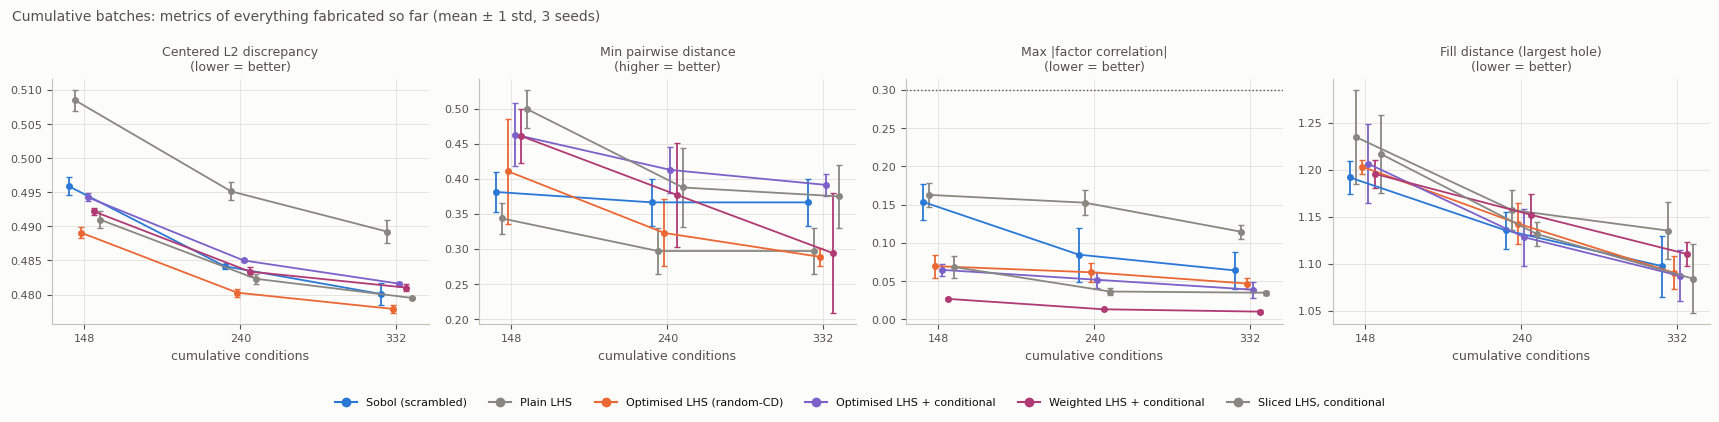

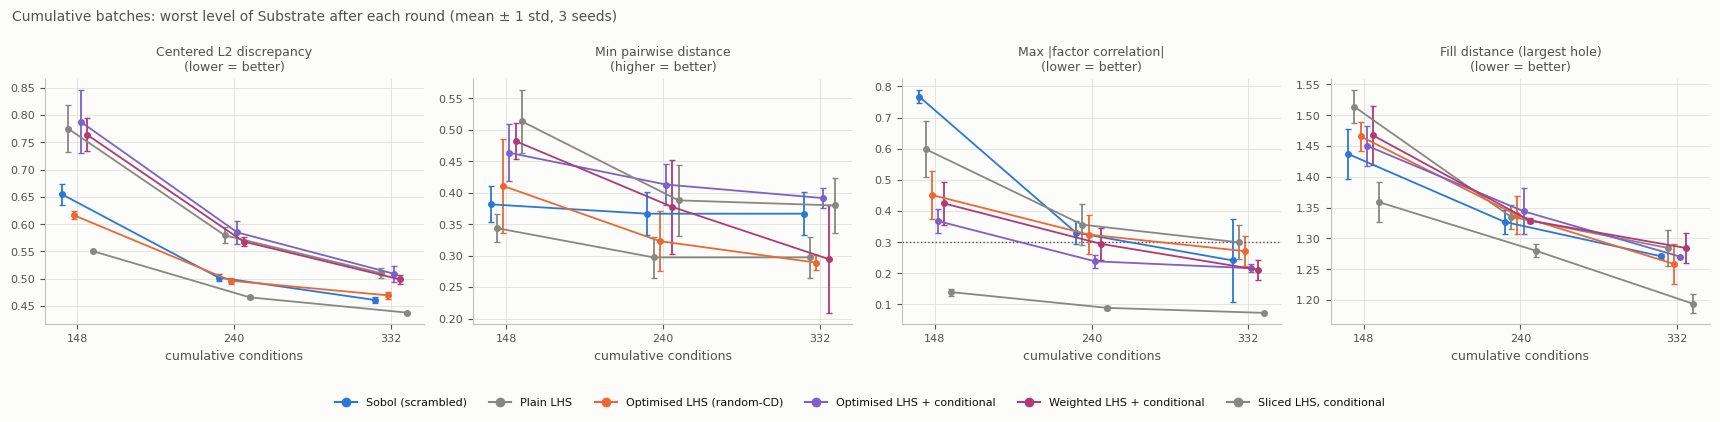

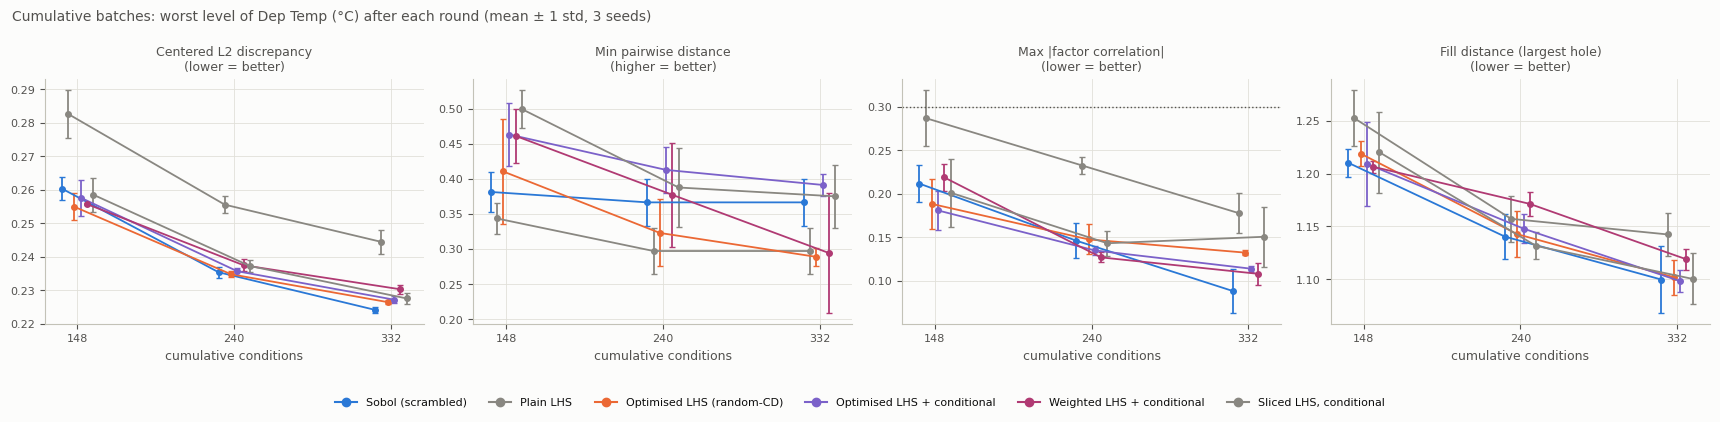

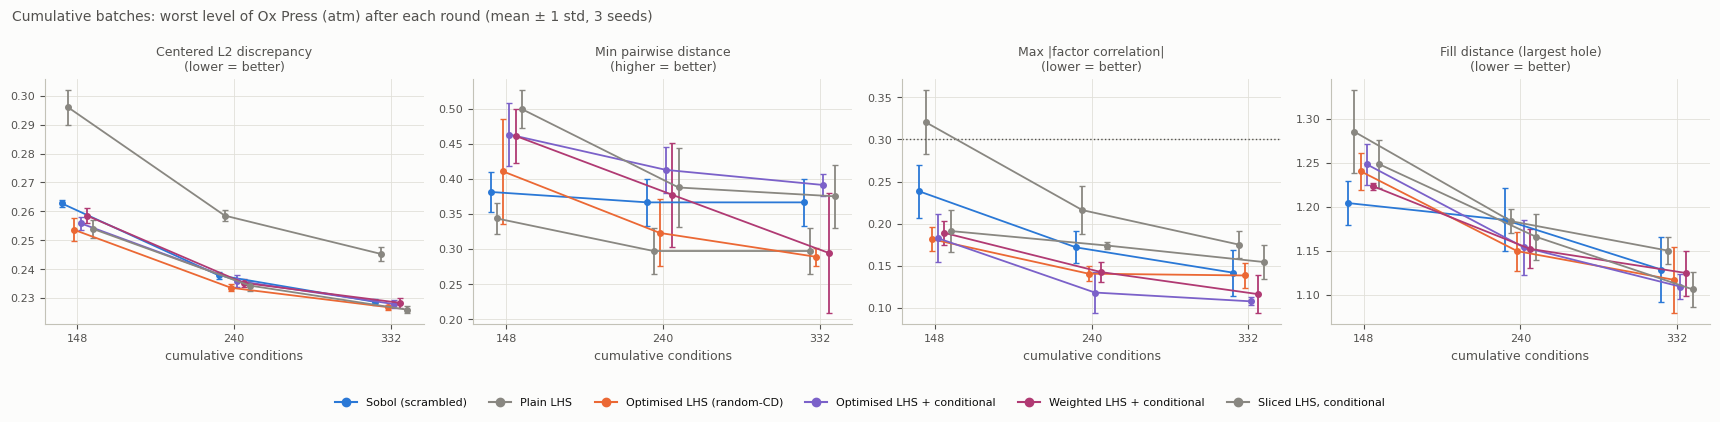

In [5]:
# ---- saving
SAVE_SEQ_FIG = False;    SEQ_FIG_FILE = 'sequential.png'
SAVE_SEQ_TABLE = False;  SEQ_TABLE_FILE = 'sequential.xlsx'
SAVE_SEQ_LEVELS_FIG = False;  SEQ_LEVELS_FIG_FILE = 'sequential_levels_{factor}.png'   # one figure per categorical factor

sq = st['sequential']; t0 = time.time()
seq = dc.sequential(space, N, sq['rounds'], sq['methods'], range(sq['seeds']), KNOWN, probes, SEQ_KW, workers=WORKERS)
print(f'{len(seq)} cumulative designs scored in {time.time() - t0:.0f} s')
seq_summary = seq.groupby(['method', 'n_cum'], sort=False)[KEYS].mean().round(3); display(seq_summary)
fig = plots.sequential_lines(seq); dc.save_fig(fig, SAVE_SEQ_FIG, os.path.join(OUT_DIR, SEQ_FIG_FILE)); plt.show()
for g_ in CATS:                                               # the same rounds, scored on the worst level of each categorical factor
    fig = plots.sequential_lines(seq, scope=g_); dc.save_fig(fig, SAVE_SEQ_LEVELS_FIG, os.path.join(OUT_DIR, SEQ_LEVELS_FIG_FILE.format(factor=''.join(ch if ch.isalnum() else '_' for ch in g_)))); plt.show()
dc.save_table({'per_seed': seq, 'summary': seq_summary}, SAVE_SEQ_TABLE, os.path.join(OUT_DIR, SEQ_TABLE_FILE))

## 4. Seed screening of one generator

Sliced LHS, conditional: 10 of 10 seeds under the |r| < 0.3 guard on the whole design, 10 also inside every level of every categorical factor; best under the guard by fill distance: seed 0 (fill 1.175, |r| 0.084)


,seed,discrepancy,min_dist,max_corr,fill_dist,max_corr@Substrate,max_corr@Dep Temp (°C),max_corr@Ox Press (atm),under_guard,under_guard_levels
0,0,0.490,0.528,0.084,1.175,0.148,0.183,0.167,True,True
1,1,0.491,0.548,0.070,1.187,0.137,0.193,0.179,True,True
5,5,0.490,0.547,0.072,1.191,0.139,0.192,0.283,True,True
6,6,0.489,0.535,0.047,1.193,0.144,0.172,0.285,True,True
2,2,0.492,0.381,0.067,1.196,0.159,0.202,0.211,True,True
9,9,0.492,0.513,0.065,1.206,0.148,0.221,0.214,True,True
4,4,0.490,0.503,0.062,1.207,0.151,0.168,0.254,True,True
3,3,0.490,0.511,0.052,1.228,0.147,0.189,0.181,True,True
7,7,0.490,0.542,0.055,1.228,0.133,0.176,0.181,True,True
8,8,0.491,0.459,0.060,1.241,0.151,0.207,0.199,True,True


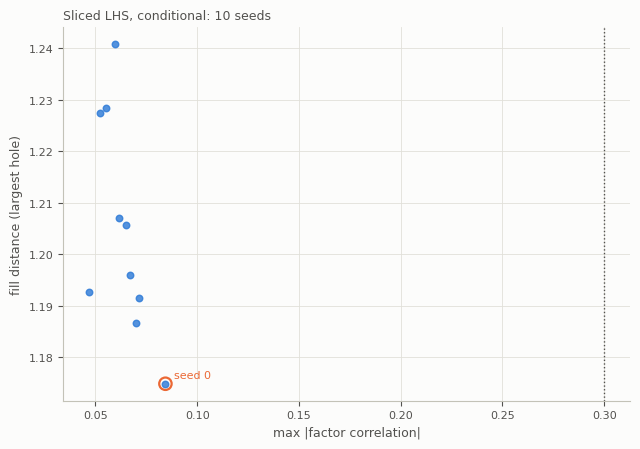

In [6]:
# ---- saving
SAVE_SCREEN_FIG = False;    SCREEN_FIG_FILE = 'seed_screening.png'
SAVE_SCREEN_TABLE = False;  SCREEN_TABLE_FILE = 'seed_screening.xlsx'

sc = st['screen']
screen, best_seed = dc.screen_seeds(space, sc['method'], N, range(sc['seeds']), GUARD, probes, workers=WORKERS, fixed=KNOWN, **SEQ_KW.get(sc['method'], {}))
print(f"{sc['method']}: {int(screen.under_guard.sum())} of {len(screen)} seeds under the |r| < {GUARD:g} guard on the whole design, {int(screen.under_guard_levels.sum())} also inside every level of every categorical factor; "
      + ('no seed under the guard' if best_seed is None else f"best under the guard by fill distance: seed {int(best_seed.seed)} (fill {best_seed.fill_dist:.3f}, |r| {best_seed.max_corr:.3f})"))
display(screen.sort_values('fill_dist').head(10)[['seed'] + KEYS + dc.level_columns(screen.columns, 'max_corr') + ['under_guard', 'under_guard_levels']].round(3))
fig = plots.seed_scatter(screen, pick_seed=None if best_seed is None else int(best_seed.seed), title=f"{sc['method']}: {len(screen)} seeds"); dc.save_fig(fig, SAVE_SCREEN_FIG, os.path.join(OUT_DIR, SCREEN_FIG_FILE)); plt.show()
dc.save_table(screen, SAVE_SCREEN_TABLE, os.path.join(OUT_DIR, SCREEN_TABLE_FILE))

## 5. The correlation-weight sweep: discrepancy + w × |r|, Pareto front and the pick — sliced optimiser, batch placed around the known recipes

optimiser: Sliced LHS | |r| term scope: whole | metrics on known + new
30 weighted designs in 25 s


discrepancy        min_dist        max_corr        fill_dist       
                   mean    std     mean    std     mean    std      mean    std
corr_weight                                                                    
0.00              0.491  0.001    0.520  0.047    0.076  0.011     1.208  0.010
0.05              0.491  0.001    0.494  0.075    0.071  0.011     1.226  0.027
0.10              0.491  0.001    0.499  0.077    0.067  0.012     1.201  0.038
0.20              0.491  0.001    0.504  0.062    0.074  0.020     1.223  0.040
0.50              0.490  0.001    0.511  0.052    0.068  0.023     1.223  0.040

,front_id,corr_weight,seed,fronts,discrepancy,min_dist,max_corr,fill_dist,max_corr@Substrate,max_corr@Dep Temp (°C),max_corr@Ox Press (atm)
0,1,0.50,3,"3-objective, corr-vs-discrepancy, corr-vs-fill...",0.490,0.438,0.044,1.267,0.147,0.173,0.226
1,2,0.10,5,"3-objective, corr-vs-fill_dist, corr-vs-min_dist",0.490,0.564,0.056,1.160,0.149,0.172,0.289
2,3,0.20,5,"3-objective, corr-vs-fill_dist, corr-vs-min_dist",0.490,0.564,0.056,1.160,0.149,0.172,0.289
3,4,0.50,5,"3-objective, corr-vs-fill_dist, corr-vs-min_dist",0.490,0.564,0.056,1.160,0.149,0.172,0.289
4,5,0.10,0,corr-vs-discrepancy,0.489,0.555,0.057,1.177,0.157,0.211,0.177
5,6,0.05,0,"3-objective, corr-vs-discrepancy, corr-vs-min_...",0.489,0.582,0.060,1.237,0.152,0.212,0.176
6,7,0.00,0,corr-vs-discrepancy,0.489,0.540,0.060,1.209,0.241,0.158,0.137
7,8,0.00,3,3-objective,0.491,0.568,0.072,1.214,0.273,0.177,0.220


automatic pick: front id 2 (w = 0.1, seed 5)  discrepancy = 0.490, min_dist = 0.564, max_corr = 0.056, fill_dist = 1.160
-> to take another front design, set SELECT in §6 to its front_id (or to a (weight, seed) pair)


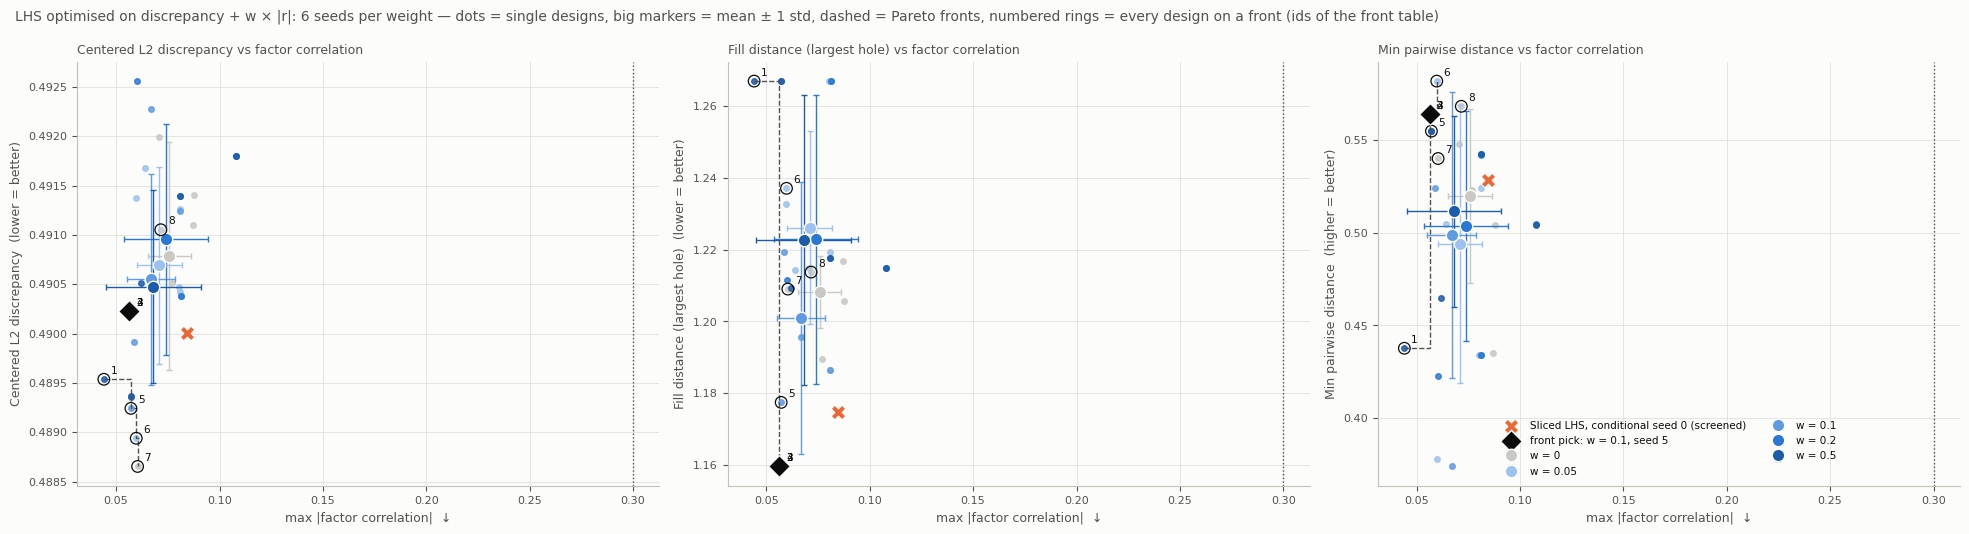

In [7]:
# ---- saving
SAVE_SWEEP_FIG = False;    SWEEP_FIG_FILE = 'corr_weight_pareto.png'
SAVE_SWEEP_TABLE = False;  SWEEP_TABLE_FILE = 'corr_weight_sweep.xlsx'

sw = st['sweep']; t0 = time.time()
sweep, U_store = dc.sweep_corr_weight(space, N, sw['weights'], range(sw['seeds']), probes, sw['n_iter'], fixed=KNOWN, workers=WORKERS, method=SWEEP_METHOD, corr_scope=CORR_SCOPE)
print('optimiser:', SWEEP_METHOD, '| |r| term scope:', CORR_SCOPE, '| metrics on known + new' if KNOWN is not None else '')
print(f'{len(sweep)} weighted designs in {time.time() - t0:.0f} s')
display(sweep.groupby('corr_weight')[KEYS].agg(['mean', 'std']).round(3))
pick = dc.pick_from_front(sweep, st['pick']['max_corr'])
refs = dict(REF_METRICS)
if best_seed is not None:
    refs[f"{sc['method']} seed {int(best_seed.seed)} (screened)"] = best_seed.to_dict()
front = dc.front_table(sweep).round(3)                      # front_id = the number printed next to each ringed design; 'fronts' says which front(s) it is on; max_corr@<factor> = its worst level
display(front)
if pick is not None:
    fid = int(front.loc[(front.corr_weight == pick.corr_weight) & (front.seed == pick.seed), 'front_id'].iloc[0])
    print(f'automatic pick: front id {fid} (w = {pick.corr_weight:g}, seed {int(pick.seed)})  ' + ', '.join(f'{k} = {pick[k]:.3f}' for k in KEYS)
          + '\n-> to take another front design, set SELECT in §6 to its front_id (or to a (weight, seed) pair)')
fig = plots.pareto_tradeoff(sweep, refs=refs, pick=None if pick is None else (float(pick.corr_weight), int(pick.seed)))
dc.save_fig(fig, SAVE_SWEEP_FIG, os.path.join(OUT_DIR, SWEEP_FIG_FILE)); plt.show()
dc.save_table({'per_design': sweep, 'front': front}, SAVE_SWEEP_TABLE, os.path.join(OUT_DIR, SWEEP_TABLE_FILE))

## 6. The chosen design

The choice is yours. `SELECT = None` takes the automatic pick of §5; `SELECT = 7` takes the front design numbered 7 in the
figure and the front table; `SELECT = (0.5, 2)` takes the sweep design with that weight and seed. `CHOICE['method']` can
also name another generator (or, with known recipes, a conditional extender) with its seed. The cell builds the new
recipes, scores them together with the known ones and alone, compares them with the references, draws the pair plot, the
correlation matrix (known + new) and the constraint plane, and prepares the run sheet (repetitions, your column order)
with its provenance.

chosen: {'method': 'Sliced LHS', 'w': 0.1, 'seed': 5} | new recipes: 92 | known recipes conditioned on: 56


,discrepancy,min_dist,max_corr,fill_dist,discrepancy@Substrate,min_dist@Substrate,max_corr@Substrate,fill_dist@Substrate,balance@Substrate,runs@Substrate,discrepancy@Dep Temp (°C),min_dist@Dep Temp (°C),max_corr@Dep Temp (°C),fill_dist@Dep Temp (°C),balance@Dep Temp (°C),runs@Dep Temp (°C),discrepancy@Ox Press (atm),min_dist@Ox Press (atm),max_corr@Ox Press (atm),fill_dist@Ox Press (atm),balance@Ox Press (atm),runs@Ox Press (atm),slice_discrepancy,slice_min_dist,slice_max_corr,slice_fill_dist,slice_balance,runs_per_slice
"CHOSEN: Sliced LHS, w = 0.1, seed 5 (known + new)",0.490198,0.564088,0.056323,1.159631,0.552003,0.612586,0.148954,1.418057,0.043203,32-46-46-24,0.252197,0.564088,0.17259,1.210866,0.042327,73-75,0.259214,0.564088,0.289172,1.247219,0.049642,73-75,0.552003,0.612586,0.148954,1.418057,0.043203,32-46-46-24
"CHOSEN: Sliced LHS, w = 0.1, seed 5 (new recipes alone)",0.532921,0.564088,0.112185,1.24532,0.588122,0.688504,0.355814,1.428562,0.025102,23-23-23-23,0.31209,0.564088,0.27345,1.304138,0.10402,46-46,0.321616,0.564088,0.359581,1.288741,0.041383,46-46,0.588122,0.688504,0.355814,1.428562,0.025102,23-23-23-23
"reference: Sliced LHS, conditional, screened seed 0",0.489987,0.528414,0.084385,1.174785,0.551123,0.569385,0.147773,1.386877,0.038276,32-46-46-24,0.257808,0.528414,0.183397,1.181084,0.084385,73-75,0.250463,0.528414,0.167251,1.260588,0.054613,73-75,0.551123,0.569385,0.147773,1.386877,0.038276,32-46-46-24


,factor,level,n,discrepancy,min_dist,max_corr,fill_dist
0,(whole design),all,148,0.490,0.564,0.056,1.160
1,Substrate,Al2O3/sapphire,32,0.533,0.689,0.133,1.306
2,Substrate,Al2O3/Si,46,0.473,0.613,0.139,1.278
3,Substrate,TiO2/Si,46,0.468,0.613,0.146,1.233
4,Substrate,HfO2/Si,24,0.552,0.875,0.149,1.418
5,Dep Temp (°C),25,73,0.252,0.613,0.173,1.211
6,Dep Temp (°C),425,75,0.249,0.564,0.132,1.198
7,Ox Press (atm),0.02,73,0.259,0.564,0.255,1.247
8,Ox Press (atm),1.0,75,0.248,0.573,0.289,1.163


,Substrate,Dep Power (W),O2 Flow (sccm),Dep Press (mTorr),Dep Temp (°C),Ox Temp (°C),Ox Press (atm),Ox Time (min),Vac Ann Temp (°C),Vac Ann Time (min),Dep Thickness (nm)
0,Al2O3/sapphire,14.0,0.8,4.2,425,600.0,0.02,39.8,105.0,51.5,4.0
1,Al2O3/sapphire,35.0,16.5,2.2,25,485.0,0.02,46.3,210.0,80.2,9.3
2,Al2O3/sapphire,22.0,17.1,4.6,25,210.0,1.0,110.2,250.0,26.7,3.4
3,Al2O3/sapphire,8.0,18.2,6.0,425,660.0,1.0,18.9,120.0,45.0,8.5
4,Al2O3/sapphire,28.0,4.7,3.8,25,570.0,0.02,88.0,195.0,20.2,9.9
...,...,...,...,...,...,...,...,...,...,...,...
87,HfO2/Si,34.0,2.8,4.5,425,260.0,1.0,84.1,220.0,35.9,1.5
88,HfO2/Si,39.0,8.5,7.1,25,350.0,0.02,63.3,80.0,78.9,5.3
89,HfO2/Si,12.0,16.9,9.0,25,415.0,1.0,9.8,205.0,56.7,5.9
90,HfO2/Si,32.0,18.0,7.3,425,500.0,0.02,33.3,195.0,28.0,9.0


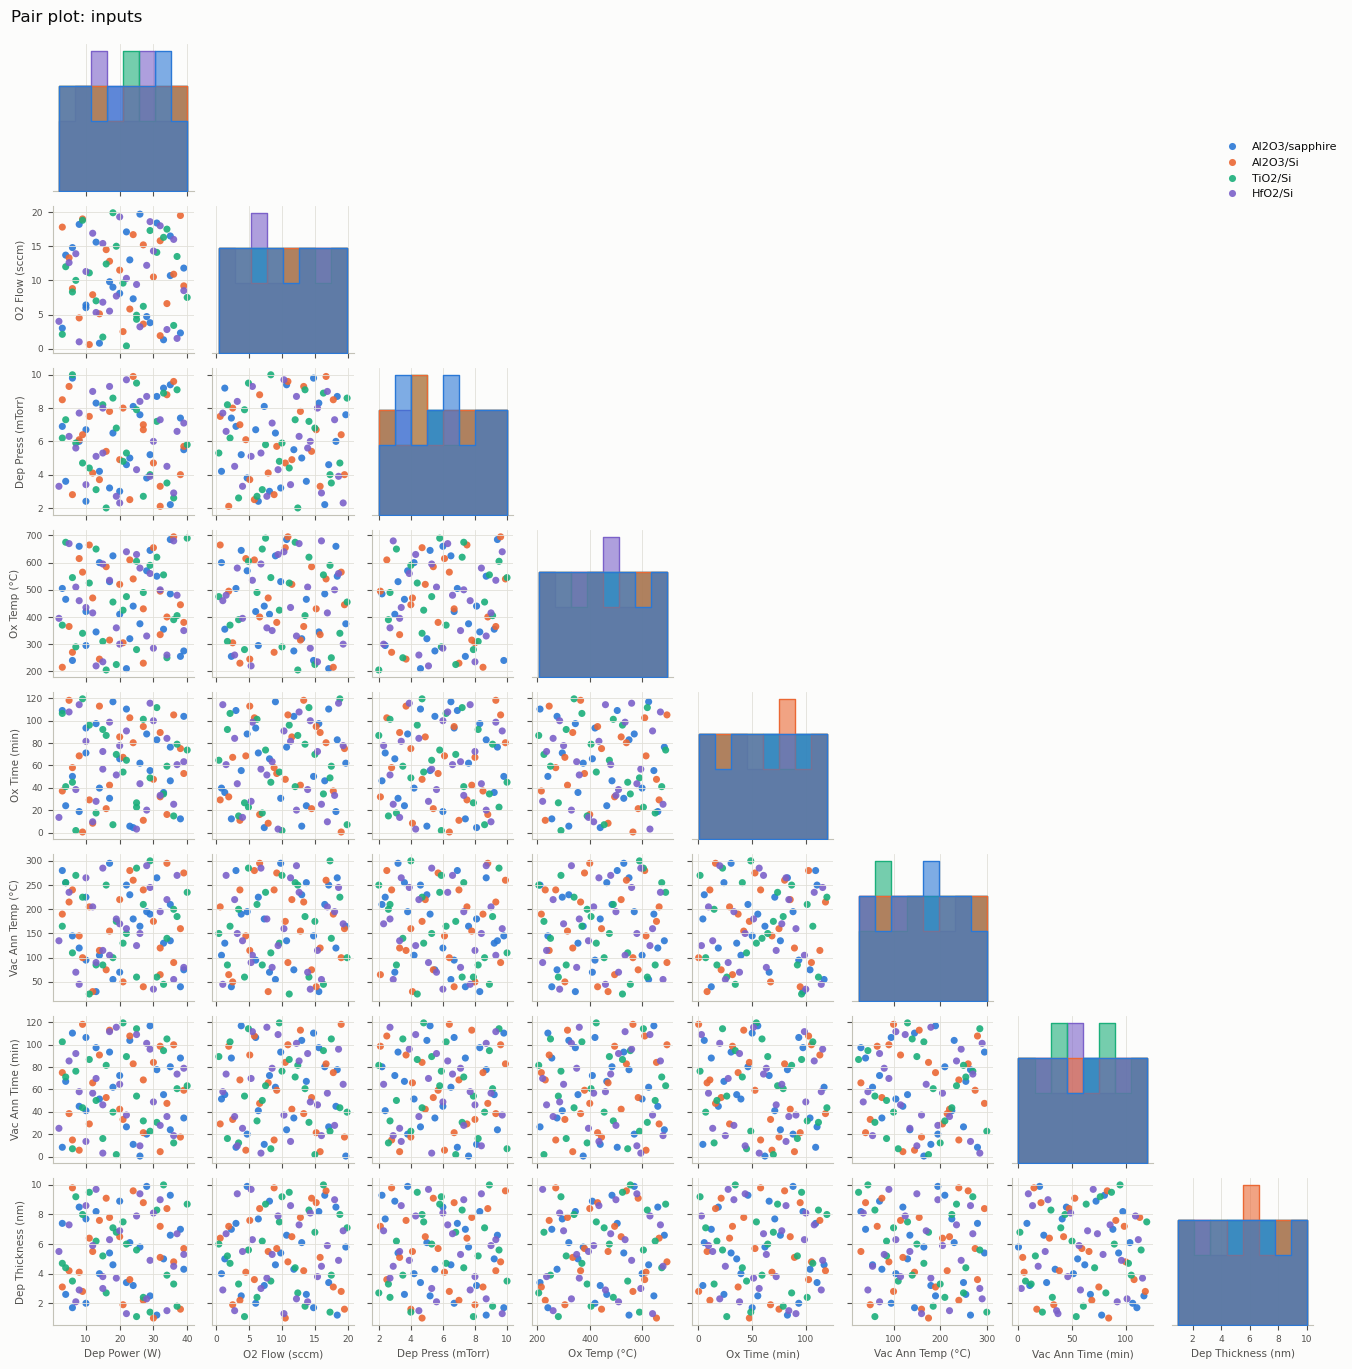

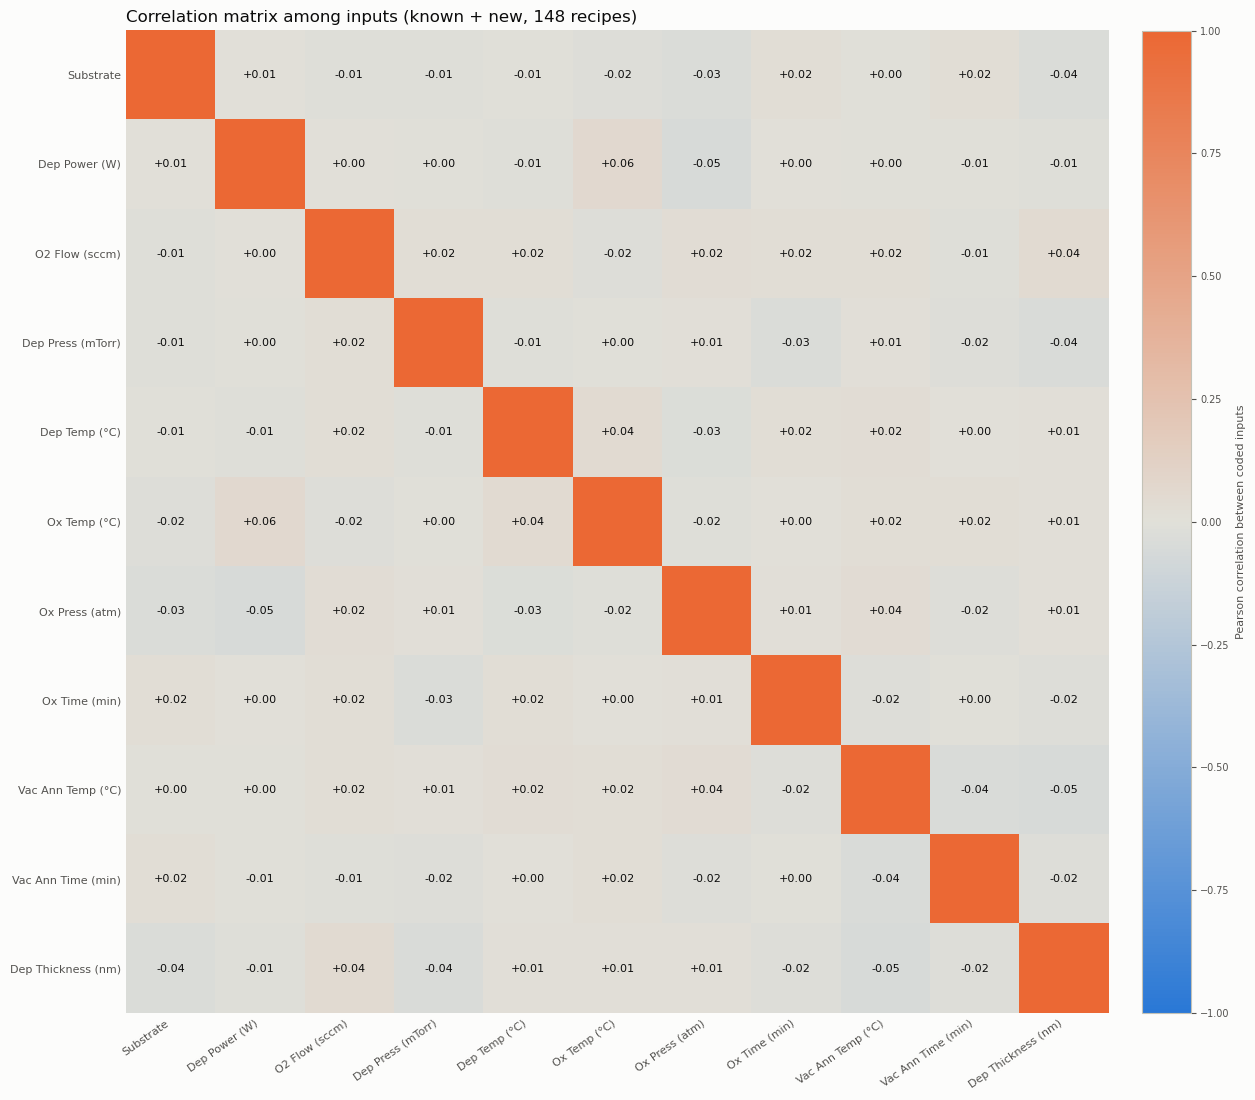

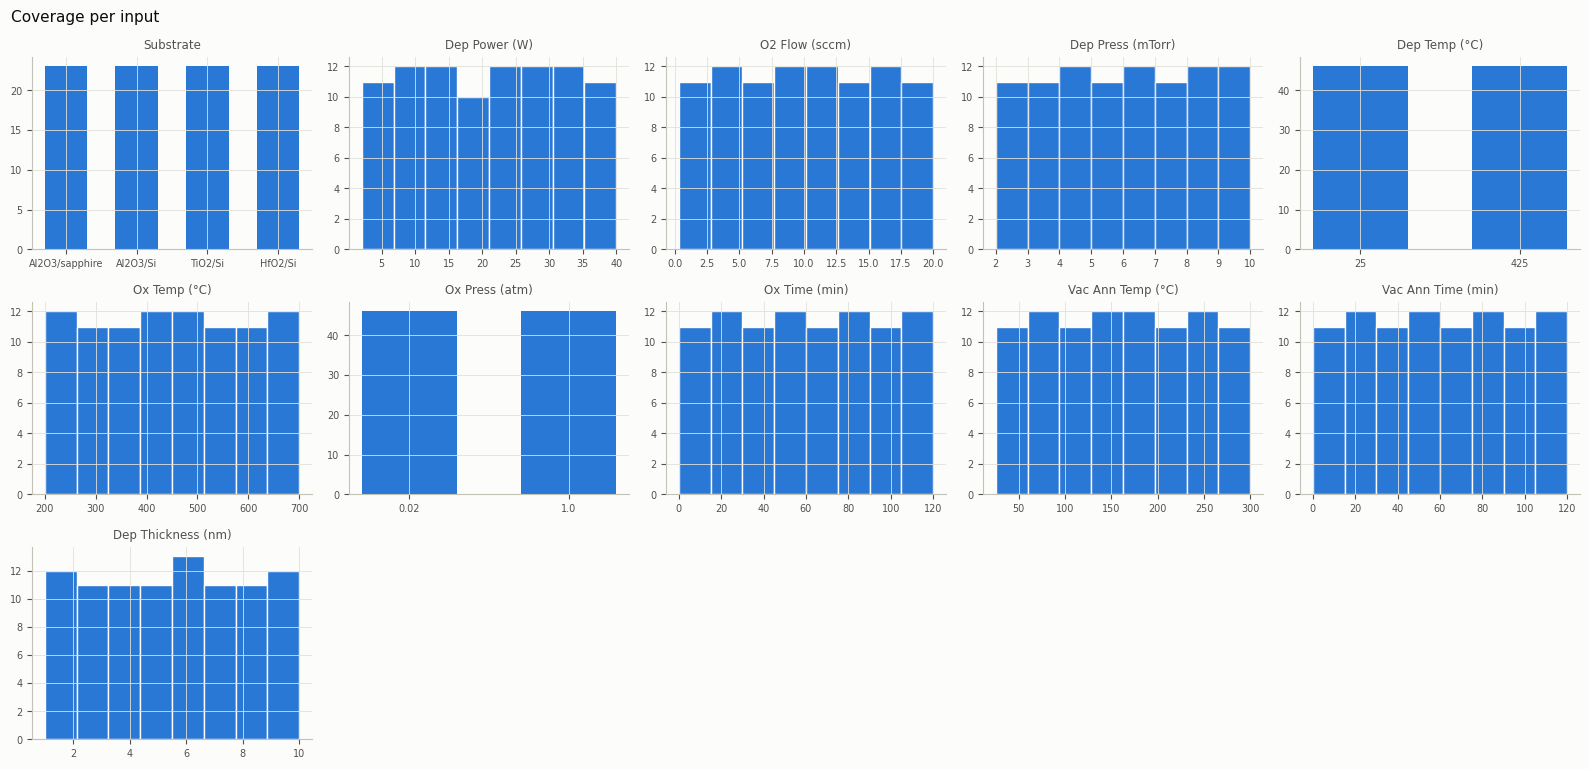

run sheet: 460 rows = 92 conditions x 5 repetitions


,Base_Run_ID,Replicate,Substrate,Dep Power (W),O2 Flow (sccm),Dep Press (mTorr),Dep Temp (°C),Ox Temp (°C),Ox Press (atm),Ox Time (min),Vac Ann Temp (°C),Vac Ann Time (min),Dep Thickness (nm)
0,1,1,Al2O3/sapphire,14.0,0.8,4.2,425,600.0,0.02,39.8,105.0,51.5,4.0
1,1,2,Al2O3/sapphire,14.0,0.8,4.2,425,600.0,0.02,39.8,105.0,51.5,4.0
2,1,3,Al2O3/sapphire,14.0,0.8,4.2,425,600.0,0.02,39.8,105.0,51.5,4.0
3,1,4,Al2O3/sapphire,14.0,0.8,4.2,425,600.0,0.02,39.8,105.0,51.5,4.0
4,1,5,Al2O3/sapphire,14.0,0.8,4.2,425,600.0,0.02,39.8,105.0,51.5,4.0
5,2,1,Al2O3/sapphire,35.0,16.5,2.2,25,485.0,0.02,46.3,210.0,80.2,9.3


saved output/pdo/four_substrates_doe_compare/design.xlsx


'output/pdo/four_substrates_doe_compare/design.xlsx'

In [9]:
# ---- saving
SAVE_DESIGN_WORKBOOK = True;    DESIGN_WORKBOOK_FILE = 'design.xlsx'
SAVE_DESIGN_PAIRPLOT = False;    DESIGN_PAIRPLOT_FILE = 'design_pairplot.png'
SAVE_DESIGN_CORRELATION = False; DESIGN_CORRELATION_FILE = 'design_correlation.png'
SAVE_DESIGN_CONSTRAINT = False;  DESIGN_CONSTRAINT_FILE = 'design_constraint_plane.png'
SAVE_DESIGN_COVERAGE = False;    DESIGN_COVERAGE_FILE = 'design_coverage.png'
SAVE_DESIGN_LEVELS = False;      DESIGN_LEVELS_FILE = 'design_levels.xlsx'

SELECT = None          # None = the automatic pick of §5; an int = a front_id from the front table / figure; (weight, seed) = any sweep design
CHOICE = dict(method=SWEEP_METHOD, w=None, seed=None)   # or e.g. dict(method='Sobol (scrambled)', w=None, seed=48) to take another generator / extender
if CHOICE['method'] == SWEEP_METHOD:
    w_, seed_, U = dc.select_design(sweep, U_store, SELECT, st['pick']['max_corr']); CHOICE.update(w=w_, seed=seed_)
elif KNOWN is not None and CHOICE['method'] in dc.EXTENDERS:
    U = dc.extend(space, CHOICE['method'], KNOWN, N, CHOICE['seed'], **SEQ_KW.get(CHOICE['method'], {}))
else:
    U = dc.generate(space, CHOICE['method'], N, CHOICE['seed'])
print('chosen:', CHOICE, '| new recipes:', len(U), '| known recipes conditioned on:', 0 if KNOWN is None else len(KNOWN))
design = space.from_unit(U)                                   # the new recipes only
label = f"CHOSEN: {CHOICE['method']}" + (f", w = {CHOICE['w']:g}" if CHOICE['w'] is not None else '') + f", seed {CHOICE['seed']}"
candidates = {label + (' (known + new)' if KNOWN is not None else ''): with_known(design)}
if KNOWN is not None:
    candidates[label + ' (new recipes alone)'] = design
if best_seed is not None:
    ref_U = (dc.extend(space, sc['method'], KNOWN, N, int(best_seed.seed), **SEQ_KW.get(sc['method'], {})) if (KNOWN is not None and sc['method'] in dc.EXTENDERS)
             else dc.generate(space, sc['method'], N, int(best_seed.seed), **SEQ_KW.get(sc['method'], {})))
    candidates[f"reference: {sc['method']}, screened seed {int(best_seed.seed)}"] = with_known(space.from_unit(ref_U))
for name, d_ in REFERENCES.items():
    candidates[f"reference: {name}"] = with_known(d_)
choice_tbl = dc.candidates_table(space, candidates, probes).round(3); display(choice_tbl)
level_tbl = dc.level_table(space, with_known(design), probes).round(3)    # the whole design and every level of every categorical factor, one row each
display(level_tbl); dc.save_table(level_tbl, SAVE_DESIGN_LEVELS, os.path.join(OUT_DIR, DESIGN_LEVELS_FILE))
display(design)

fig = plots.pairplot(design, space); dc.save_fig(fig, SAVE_DESIGN_PAIRPLOT, os.path.join(OUT_DIR, DESIGN_PAIRPLOT_FILE)); plt.show()
fig = plots.correlation_heatmap(with_known(design), space, title='Correlation matrix among inputs' + (f' (known + new, {len(with_known(design))} recipes)' if KNOWN is not None else ''))
dc.save_fig(fig, SAVE_DESIGN_CORRELATION, os.path.join(OUT_DIR, DESIGN_CORRELATION_FILE)); plt.show()
if space.constraints:
    fig = plots.constraint_plane(design, space, ylim=st.get('plane_ylim')); dc.save_fig(fig, SAVE_DESIGN_CONSTRAINT, os.path.join(OUT_DIR, DESIGN_CONSTRAINT_FILE)); plt.show()
fig = plots.coverage_hist(design, space); dc.save_fig(fig, SAVE_DESIGN_COVERAGE, os.path.join(OUT_DIR, DESIGN_COVERAGE_FILE)); plt.show()

m = dc.evaluate(space, with_known(design), probes)       # what the model will see: known + new
for k_, v_ in CONSTANTS.items():
    design[k_] = v_                                          # pinned columns for the sheet
sheet = dc.run_sheet(design, REPS, st['id_col'], st['rep_col'], st['sheet_columns'])
prov = dc.provenance_table(campaign=space.name, config=CONFIG, generator=CHOICE['method'], seed=CHOICE['seed'], corr_weight=CHOICE['w'], corr_scope=CORR_SCOPE,
                           n=N, repetitions=REPS, known=(f'{len(KNOWN_DF)} recipes already in hand, inside the bounds, conditioned on' if KNOWN is not None else 'none'),
                           metrics=('known + new: ' if KNOWN is not None else '') + ', '.join(f'{k} = {v:.3f}' for k, v in m.items() if isinstance(v, float)),
                           written=pd.Timestamp.today().strftime('%Y-%m-%d'))
print(f'run sheet: {len(sheet)} rows = {N} conditions x {REPS} repetitions'); display(sheet.head(6))
dc.save_table({'design_full': sheet, 'design_unique': design, 'config': space.describe(), 'provenance': prov, 'candidates': choice_tbl.rename_axis('design').reset_index(),
               'levels': level_tbl, **({'known_recipes': KNOWN_DF} if KNOWN is not None else {})},
              SAVE_DESIGN_WORKBOOK, os.path.join(OUT_DIR, DESIGN_WORKBOOK_FILE))

## 7. Reading the results

Use the tables and figures above to answer, for this design space: which generator is best for one batch (§2), which keeps
spacing and holes as batches accumulate (§3), how much the seed matters (§4), what the correlation penalty buys and costs (§5),
and whether the chosen design (§6) clears the |r| guard with the structural pairs reported separately. Write the verdict here.